# GP Regression for predicting next hour demand
Student Names: Oliver Wuttke

Student FAN: WUTT0019

File: bayesian_investigation.ipynb

Date: 02-11-2026

Description: Fitting and evaluation of GP Regression model on our dataset.

In [80]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel

In [81]:
# Load in our data
df = pd.read_parquet("../data/processed/electricity_transformed.parquet").set_index("timestamp")

# Lag features
df["y"] = df["demand"].shift(-1)
df["demand_lag_23h"] = df["demand"].shift(23)
df["demand_lag_167h"] = df["demand"].shift(167)

# Cos/sin encode our hours since 24 hour time is periodic
h = (df.index + pd.Timedelta(hours=1)).hour
df["hour_sin"] = np.sin(2 * np.pi * h / 24)
df["hour_cos"] = np.cos(2 * np.pi * h / 24)

In [82]:
# GP is expensive on larger datasets n^3 inference, so we only take the following
FEATURES = ["demand", "demand_lag_1h", "demand_lag_23h", "demand_lag_167h",
            "hour_sin", "hour_cos", "is_weekend"]
df = df.dropna(subset=FEATURES + ["y"])

X = df[FEATURES].to_numpy()
now = df["demand"].to_numpy()
y = df["y"].to_numpy() - now

In [83]:
# Constructs a GP regressor object with a given kernel
def gp(kernel, tune):
    return GaussianProcessRegressor(
        kernel, normalize_y=True, optimizer="fmin_l_bfgs_b" if tune else None)

In [84]:
# Rolling window and step size
WINDOW, STEP = 24 * 30, 24 * 7

# Test period starts here for model eval
start = df.index.searchsorted(pd.Timestamp("2025-09-24", tz=df.index.tz))

In [85]:
# Pick all rows from last 30 days
sub = np.arange(start - WINDOW, start)

In [86]:
kernel = ConstantKernel() * Matern(length_scale=np.ones(len(FEATURES)), nu=2.5) + WhiteKernel()

In [87]:
# Fit scaler and gp model on training sample
sx = StandardScaler().fit(X[sub])
kernel = gp(kernel, tune=True).fit(sx.transform(X[sub]), y[sub]).kernel_
print(kernel)

1.69**2 * Matern(length_scale=[2.01, 2.3, 10.3, 16.5, 2.07, 0.791, 31.2], nu=2.5) + WhiteKernel(noise_level=0.0342)


In [88]:
# Make predictions with uncertainty
preds, stds, past = [], [], []   # past: (|z|, hour) from earlier weeks
for o in range(start, len(df), STEP):
    sx = StandardScaler().fit(X[o - WINDOW:o])
    model = gp(kernel, tune=False).fit(sx.transform(X[o - WINDOW:o]), y[o - WINDOW:o])
    m, s = model.predict(sx.transform(X[o:o + STEP]), return_std=True)

    # scale std per hour using errors from the previous 12 weeks (already observed)
    hrs = (df.index[o:o + STEP] + pd.Timedelta(hours=1)).hour.to_numpy()
    if len(past) >= 4:
        z = np.concatenate([p[0] for p in past[-12:]])
        hz = np.concatenate([p[1] for p in past[-12:]])
        scale = np.array([np.quantile(z[hz == i], 0.95) / 1.96 for i in range(24)])
        s = s * scale[hrs]

    past.append((np.abs(y[o:o + STEP] - m) / s, hrs))
    preds.append(m)
    stds.append(s)

In [89]:
# Convert results into a pandas dataframe
res = pd.DataFrame({
    "actual": df["y"].to_numpy()[start:],
    "pred": now[start:] + np.concatenate(preds),
    "std": np.concatenate(stds),
    "persistence": now[start:],
}, index=df.index[start:] + pd.Timedelta(hours=1))

In [90]:
def metrics(p):
    e = res.actual - p
    return {
        "MAE": np.mean(np.abs(e)),
        "RMSE": np.sqrt(np.mean(e**2)),
        "MAPE %": 100 * np.mean(np.abs(e / res.actual)),
        "R^2": 1 - np.sum(e**2) / np.sum((res.actual - res.actual.mean())**2),
    }

table = pd.DataFrame({"GP": metrics(res.pred), "persistence": metrics(res.persistence)}).T
table["skill vs persistence"] = 1 - table["RMSE"] / table.loc["persistence", "RMSE"]

coverage = np.mean(np.abs(res.actual - res.pred) <= 1.96 * res["std"])
print(f"95% band coverage: {coverage:.3f}")
table.round(3)

95% band coverage: 0.915


,MAE,RMSE,MAPE %,R²,skill vs persistence
GP,117.951,190.895,1.661,0.982,0.615
persistence,392.633,496.084,5.337,0.882,0.000


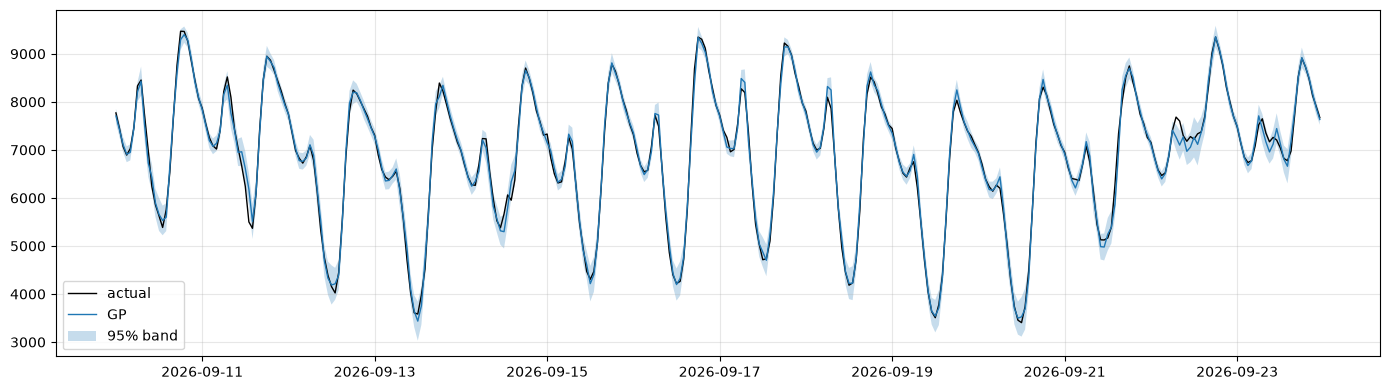

In [91]:
z = res.iloc[-24 * 14:]
plt.figure(figsize=(14, 4))
plt.plot(z.index, z.actual, "k", lw=1, label="actual")
plt.plot(z.index, z.pred, lw=1, label="GP")
plt.fill_between(z.index, z.pred - 1.96 * z["std"], z.pred + 1.96 * z["std"], alpha=0.25, label="95% band")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()